In [102]:
import os

import pandas as pd

from solution_utils import (
    compute_metrics, compute_partition_metrics, init_reaction_models, init_topic_models,
    predict_reaction, predict_topic, read_dialogs, read_labels, save_predictions, normalize
)

In [86]:
import os
if os.environ.get("HW1_DATA") is None:
    os.environ["HW1_TRAIN"] = "data/hw1_train.jsonl"
    os.environ["HW1_DATA"] = "data/hw1_train.jsonl"
    os.environ["HW1_LABELS"] = "data/hw1_train.jsonl"
    os.environ["HW1_PREDICTIONS"] = "artifacts/predictions.jsonl"

In [87]:
TRAIN_PATH = os.environ.get("HW1_TRAIN", "hw1_train.jsonl")
DATA_PATH = os.environ.get("HW1_DATA", "hw1_train.jsonl")
LABELS_PATH = os.environ.get("HW1_LABELS", DATA_PATH)
PREDICTIONS_PATH = os.environ.get("HW1_PREDICTIONS", "predictions.csv")

dialogs = read_dialogs(DATA_PATH)
print("диалогов:", len(dialogs))

диалогов: 10000


## Разведочный анализ данных (EDA)

### Блок 1. Что за данные

In [88]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter

def get_reaction(labels):
    if labels is None:
        return None
    return labels.get('reaction')

def get_task_type(labels):
    if labels is None:
        return None
    return labels.get('task_type')


raw_records = []
with open(DATA_PATH, encoding='utf-8') as f:
    for line in f:
        if line.strip():
            raw_records.append(json.loads(line))

raw = pd.DataFrame(raw_records)

print("Диалогов:", raw.shape[0])
print("Столбцы:", list(raw.columns))

raw['reaction']  = raw['labels'].apply(get_reaction)
raw['task_type'] = raw['labels'].apply(get_task_type)
raw['language']  = raw.get('language', 'unknown')

print()
print("Языки")
print(raw['language'].value_counts())

print()
print("Реакция пользователя")
print(raw['reaction'].value_counts(dropna=False))

print()
overall_share = raw['reaction'].value_counts(normalize=True)
print("Доли классов:")
print(overall_share.round(3))

Диалогов: 10000
Столбцы: ['dialog_id', 'language', 'n_user_turns', 'turns', 'labels']

Языки
language
en    9929
ru      71
Name: count, dtype: int64

Реакция пользователя
reaction
NaN         7000
neutral     1774
negative     923
positive     303
Name: count, dtype: int64

Доли классов:
reaction
neutral     0.591
negative    0.308
positive    0.101
Name: proportion, dtype: float64


### Блок 2. Целостность

In [89]:
uniq = raw['dialog_id'].nunique()
total = raw.shape[0]
if uniq == total:
    print('Все уникальные')
else: 
    print('Есть совпадения:', total - uniq)

print()
print('Количество пропусков в столбце меток', raw['labels'].isna().sum())
print('Количество пропусков в столбце айдишников', raw['dialog_id'].isna().sum())
print('Количество пропусков в столбце реплик', raw['turns'].isna().sum())

n_empty = (raw['n_user_turns'] == 0).sum()
print()
print('Диалогов с пустым turns репликами:', n_empty)
n_labeled = raw['reaction'].notna().sum()
print()
print('Непустых реакций:', n_labeled)


Все уникальные

Количество пропусков в столбце меток 7000
Количество пропусков в столбце айдишников 0
Количество пропусков в столбце реплик 0

Диалогов с пустым turns репликами: 0

Непустых реакций: 3000


dialog_id все 10000 уникальны, дубликатов нет. 7000 это неразмеченные данные.

Поля dialog_id и turns заполнены у всех.

Метка reaction есть только у 3000 из 10000.

Гипотеза про 7000 без метки: возможно, это промежуточные ходы диалога, где пользователь ещё не дал финальную реакцию.

Решение: обучаемся и оцениваемся только на 3000 размеченных.

Проверим если метка ставится в конце разговора, то у неразмеченных должно быть меньше реплик.

In [90]:
raw['has_label'] = raw['reaction'].notna()
print(raw.groupby('has_label')['n_user_turns'].agg(['mean', 'median', 'min', 'max']))

               mean  median  min  max
has_label                            
False      6.705286     6.0    5   10
True       6.683667     6.0    5   10


длина диалога не зависит от того, размечен он или нет. То есть среди 7000 неразмеченных диалогов реплик столько же, сколько среди 3000 размеченных.

## Блок 3. Классы

In [91]:
#print(raw['task_type'])
print()
print('Уникальные типы задач: ', raw['task_type'].nunique())
print()
print('Как часто встречаются типы задач:') 
print(raw['task_type'].value_counts(dropna=False))
print()
overall_share = raw['reaction'].value_counts(normalize=True)
print("Доли классов:")
print(overall_share.round(3))
print()
task_t = raw['task_type'].value_counts(normalize=True)
print("Доли типов задач:")
print(task_t.round(3))


Уникальные типы задач:  4

Как часто встречаются типы задач:
task_type
NaN                     7000
information_seeking     1831
creation                 944
analysis                 137
open-ended_discovery      88
Name: count, dtype: int64

Доли классов:
reaction
neutral     0.591
negative    0.308
positive    0.101
Name: proportion, dtype: float64

Доли типов задач:
task_type
information_seeking     0.610
creation                0.315
analysis                0.046
open-ended_discovery    0.029
Name: proportion, dtype: float64


In [92]:
print(pd.crosstab(raw['reaction'], raw['task_type']))

task_type  analysis  creation  information_seeking  open-ended_discovery
reaction                                                                
negative         58       223                  629                    13
neutral          61       650                 1020                    43
positive         18        71                  182                    32


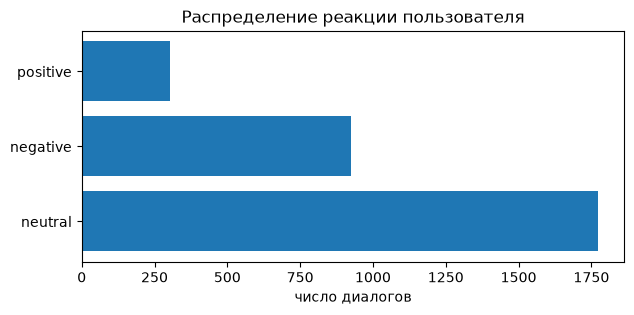

In [93]:
mask = raw['reaction'].notna()
only_label = raw[mask]

counts = only_label['reaction'].value_counts()

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(counts.index, counts.values)
ax.set_xlabel("число диалогов")
ax.set_title("Распределение реакции пользователя")
plt.show()

### Как связаны task_type и reaction

Внутри каждого типа задачи доли реакций разные:

| task_type | negative | neutral | positive |
|:--|--:|--:|--:|
| analysis | 42.3% | 44.5% | 13.1% |
| creation | 23.6% | 68.9% | 7.5% |
| information_seeking | 34.4% | 55.7% | 9.9% |
| open-ended_discovery | 14.8% | 48.9% | 36.4% |
| **по выборке** | 30.8% | 59.1% | 10.1% |

Если бы признаки были независимы, все строки совпадали бы с итоговой. У нас
у open-ended_discovery доля positive 36.4% против среднего 10.1%, у analysis
доля negative 42.3% против 30.8% , значит есть заметная связь. То есть пользователи
довольны чаще на открытых запросах и недовольны чаще на аналитических.
Формальная проверка (хи-квадрат, V Крамера) подтверждает связь, но она умеренная:
даже внутри одной task_type доля negative около 34%, а не 0% или 100%.

In [94]:
from scipy.stats import chi2_contingency
ct = pd.crosstab(raw['reaction'], raw['task_type'])
chi2, p_value, dof, expected = chi2_contingency(ct.to_numpy(), correction=False)
n = ct.to_numpy().sum()

r, c = ct.shape
v_cramer = np.sqrt(chi2 / (n * (min(r, c) - 1)))

print('chi2 = ',chi2.round(3))
print('p-value = ', p_value)
print('V Крамера = ', v_cramer.round(3))

chi2 =  129.441
p-value =  1.6854043833592435e-25
V Крамера =  0.147


### Проверка связи task_type и reaction

Хи-квадрат = 129.4, p-value ≈ 1.7·10⁻²⁵. Гипотеза о независимости отвергается. Связь между типом задачи и реакцией не случайна.

хи-квадрат о силе связи ничего не говорит на 3000 объектах. Нормированная мера V Крамера = 0.147 умеренная связь.
task_type интересный сигнал для задачи 1, но одна только
она реакцию не объясняет. Остальное зависит от качества конкретного ответа модели,
индивидуальные ожидания пользователя, контекст ходов.

In [95]:
from sklearn.metrics import accuracy_score, f1_score

mask = raw['reaction'].notna()
y = raw.loc[mask, 'reaction'].to_numpy()
print(y)
print()
pred_const = np.array(['neutral'] * len(y))
print(pred_const)
print("accuracy :", round(accuracy_score(y, pred_const), 3))
print("macro-F1 :", round(f1_score(y, pred_const, average='macro'), 3))

['positive' 'neutral' 'neutral' ... 'neutral' 'negative' 'negative']

['neutral' 'neutral' 'neutral' ... 'neutral' 'neutral' 'neutral']
accuracy : 0.591
macro-F1 : 0.248


### Метрика macro-F1 подойдет лучше чем accuracy

Реакции распределены как 59% / 31% / 10% (neutral / negative / positive).
Константа выбирать всегда neutral даёт accuracy 0.59, а macro-F1 0.247,
потому что F1 для positive и negative равен нулю. Значит accuracy при таком
дисбалансе обманывает, т.е. показывает в основном долю большинства классов. Macro-F1
усредняет три класса с одинаковым весом, поэтому подходит для этой задачи.
Дополнительно смотрим accuracy, сбалансированную accuracy, precision/recall
по классам и матрицу ошибок.

In [ ]:
for label in ['negative', 'neutral', 'positive']:
    mask = raw['reaction'] == label
    itog = raw[mask]
    words = []
    for turns in itog['turns']:
        for turn in turns:
            if turn['role'] == 'user':
               text = ' ' + turn['text']
               text_redak = normalize(text)
               words.extend(text_redak)
    top = Counter(words).most_common(15)
    print(label, top)



negative [('data', 1483), ('use', 1389), ('file', 1225), ('return', 1188), ('valu', 1159), ('model', 1141), ('self', 1103), ('text', 966), ('name', 965), ('import', 934), ('code', 913), ('size', 880), ('line', 876), ('error', 861), ('get', 837)]
neutral [('use', 2482), ('write', 1541), ('make', 1435), ('one', 1175), ('time', 1137), ('like', 1092), ('data', 1072), ('provid', 999), ('would', 965), ('new', 965), ('valu', 940), ('follow', 908), ('return', 898), ('also', 897), ('need', 895)]
positive [('use', 417), ('like', 282), ('make', 264), ('thank', 248), ('would', 222), ('one', 208), ('model', 195), ('pleas', 192), ('could', 181), ('also', 179), ('true', 173), ('want', 166), ('work', 163), ('prompt', 158), ('new', 154)]


### Топ-слова по реакции

После обработки пользовательских реплик получаем 15 самых частых основ для каждой реакции:

-positive 303 диалога: use, like, make, thank, would, one, model, pleas, could, also, true, want, work, prompt, new.

-neutral (1774): use, write, make, one, time, like, data, provid, would, new, valu, follow, return, also, need.

-negative (923): data, use, file, return, valu, model, self, text, name, import, code, size, line, error, get.

Positive узнаваем по лексике благодарности: thank, pleas, true.

У negative почти нет слов вроде wrong, no,
again, repeat. Массово встречаются программистские термины: data,
file, code, import, error, return, size, line. Похоже, что
негативные реакции концентрируются на диалогах, где пользователь работал
с кодом или спрашивал про данные, а модель отвечала неудачно. То есть
негативная реакция в этом корпусе коррелирует с типом задачи сильнее,
чем с эмоциональной лексикой.

Neutral без выраженной лексики, там просто обычные
частотные слова.

Пересечение топ-15:
- positive и neutral — 7 слов (`use`, `like`, `make`, `would`, `one`, `also`, `new`);
- negative и neutral — 5 слов (`data`, `use`, `return`, `valu`, `model`);
- positive и negative — 3 слова (`use`, `make`, `model`).

Вывод: словарного сигнала для разделения neutral и negative мало, потому
что в обоих классах лидируют одни и те же частые слова. Positive, наоборот,
отделяется лексикой благодарности, и по нему модель может показать хороший
F1 даже несмотря на то, что это самый редкий класс.

Это ожидание подтверждает вывод из crosstab: реакция связана с типом задачи
сильнее, чем с эмоциональными словами пользователя. Поэтому в задаче 1
попробую добавить в признаки текст + структурные
признаки: длину диалога, длину последней реплики, тип задачи.

## Блок 4. Длины текстов и чистка

Гипотезы: Negative реплики длиннее, чем positive. Потому что если пользователь пишет код или объясняет проблему, он пишет много.

Positive пользовательские реплики короче thanks, great, continue.

Assistant-реплики в negative могут быть тоже длиннее, так как модель пытается объяснить, когда её поправляют.

In [115]:
for label in ['negative', 'neutral', 'positive']:
    mask = raw['reaction'] == label
    itog = raw[mask]
    quantity_wordsU = []
    len_wordsU = []
    quantity_wordsA = []
    len_wordsA = []

    for turns in itog['turns']:
        for turn in turns:
            if turn['role'] == 'user':
               len_wordsU.append(len(turn['text']))
               words = turn['text'].split()
               quantity_wordsU.append(len(words))
            if turn['role'] == 'assistant':
                len_wordsA.append(len(turn['text']))
                words = turn['text'].split()
                quantity_wordsA.append(len(words))
    print(label, 'Символы пользователя: ' , np.mean(len_wordsU), np.median(len_wordsU), np.percentile(len_wordsU, [25, 50, 75]), 'Колличество слов пользователя: ', np.mean(quantity_wordsU), np.median(quantity_wordsU), np.percentile(quantity_wordsU, [25, 50, 75]))
    print(label, 'Символы слов ассистента: ' , np.mean(len_wordsA), np.median(len_wordsA), np.percentile(len_wordsA, [25, 50, 75]) , 'Колличество слов ассистента: ', np.mean(quantity_wordsA), np.median(quantity_wordsA), np.percentile(quantity_wordsA, [25, 50, 75]))



negative Символы пользователя:  408.6162996302845 86.0 [ 42.  86. 249.] Колличество слов пользователя:  54.79456678990516 15.0 [ 8. 15. 39.]
negative Символы слов ассистента:  1497.9091785886512 1256.0 [ 603. 1256. 2135.] Колличество слов ассистента:  214.85725767561485 189.0 [ 94. 189. 300.]
neutral Символы пользователя:  348.5214431586113 90.0 [ 46.    90.   226.25] Колличество слов пользователя:  52.498893805309734 15.0 [ 8. 15. 37.]
neutral Символы слов ассистента:  1573.172396187883 1339.5 [ 579.75 1339.5  2345.25] Колличество слов ассистента:  236.2245575221239 208.0 [ 90. 208. 351.]
positive Символы пользователя:  299.6737247353224 77.0 [ 37.  77. 188.] Колличество слов пользователя:  46.20644850818094 14.0 [ 7. 14. 33.]
positive Символы слов ассистента:  1278.6655437921079 963.5 [ 336.25  963.5  1915.75] Колличество слов ассистента:  194.6708373435996 153.0 [ 55. 153. 292.]


### Длины реплик по классам реакции

Для каждой реплики посчитали длину в символах и число слов, отдельно для user
и assistant. Медианы и квартили (25–50–75):

| класс | user, символов | user, слов | assistant, символов | assistant, слов |
|:--|--:|--:|--:|--:|
| negative | 86 | 15 | 1256 | 189 |
| neutral | 90 | 15 | 1339 | 208 |
| positive | 77 | 14 | 963 | 153 |

Два вывода:

Длина пользовательских реплик почти не различает классы. Медиана везде 14–15 слов,
   квартили тоже близки. Значит, гипотеза в negative пользователи пишут длиннее
   не подтвердилась.

Ответы ассистента в positive короче по медиане. Positive median
   963 символа, neutral median 1339, negative 1256. То есть когда пользователь
   доволен, ответы модели короче и точнее; длинные ответы чаще получают нейтральную
   или негативную оценку. Это уже потенциальный признак для задачи 1.

Распределения сильно скошены вправо: у user среднее около 300–400 символов при
медиане 77–90. Это значит, что есть небольшие типичные реплики и редкие
гигантские (код, копипаста, длинные объяснения).

В признаки задачи 1 можно добавить длину последней user-реплики, длину всех
user-реплик, а длина ассистентского
ответа в positive-диалогах явно меньше.

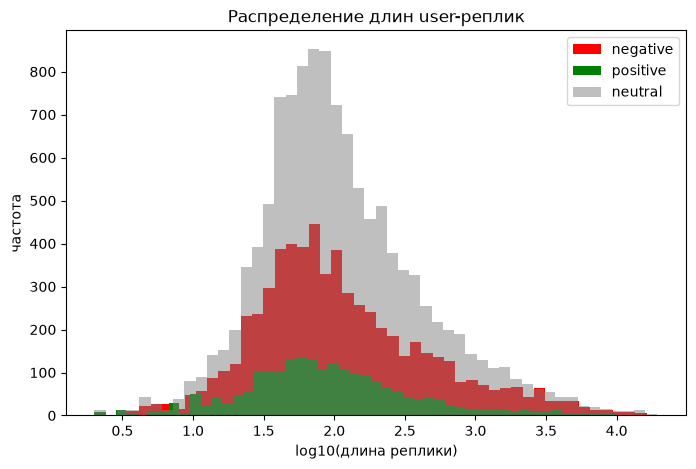

In [142]:
lengths_by_label = {}
for label in ['negative', 'neutral', 'positive']:
    mask = raw['reaction'] == label
    itog = raw[mask]
    quantity_wordsU = []
    len_wordsU = []
    quantity_wordsA = []
    len_wordsA = []

    for turns in itog['turns']:
        for turn in turns:
            if turn['role'] == 'user':
               len_wordsU.append(len(turn['text']))
               words = turn['text'].split()
               quantity_wordsU.append(len(words))
            if turn['role'] == 'assistant':
                len_wordsA.append(len(turn['text']))
                words = turn['text'].split()
                quantity_wordsA.append(len(words))
    lengths_by_label[label] = {"user": len_wordsU, "assistant": len_wordsA}
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(np.log10(np.array(lengths_by_label["negative"]["user"]) + 1), bins=50, alpha=1, label="negative", color="red")
ax.hist(np.log10(np.array(lengths_by_label["positive"]["user"]) + 1), bins=50, alpha=1, label="positive", color="green")
ax.hist(np.log10(np.array(lengths_by_label["neutral"]["user"]) + 1), bins=50, alpha=0.5, label="neutral", color="gray")
ax.set_xlabel("log10(длина реплики)")
ax.set_ylabel("частота")
ax.set_title("Распределение длин user-реплик")
ax.legend()
plt.show()

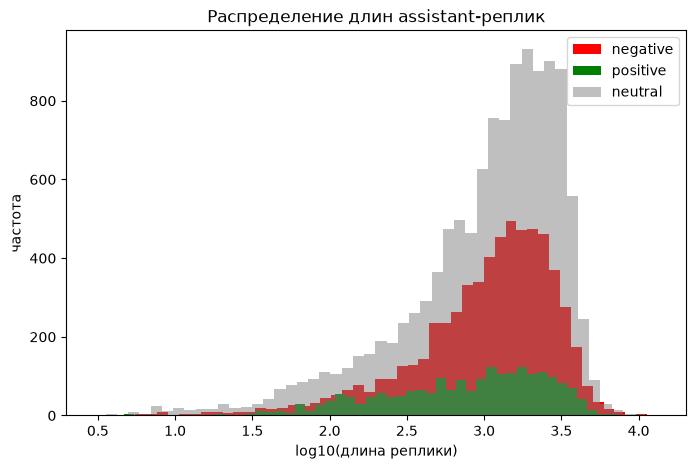

In [143]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(np.log10(np.array(lengths_by_label["negative"]["assistant"]) + 1), bins=50, alpha=1, label="negative", color="red")
ax.hist(np.log10(np.array(lengths_by_label["positive"]["assistant"]) + 1), bins=50, alpha=1, label="positive", color="green")
ax.hist(np.log10(np.array(lengths_by_label["neutral"]["assistant"]) + 1), bins=50, alpha=0.5, label="neutral", color="gray")
ax.set_xlabel("log10(длина реплики)")
ax.set_ylabel("частота")
ax.set_title("Распределение длин assistant-реплик")
ax.legend()
plt.show()

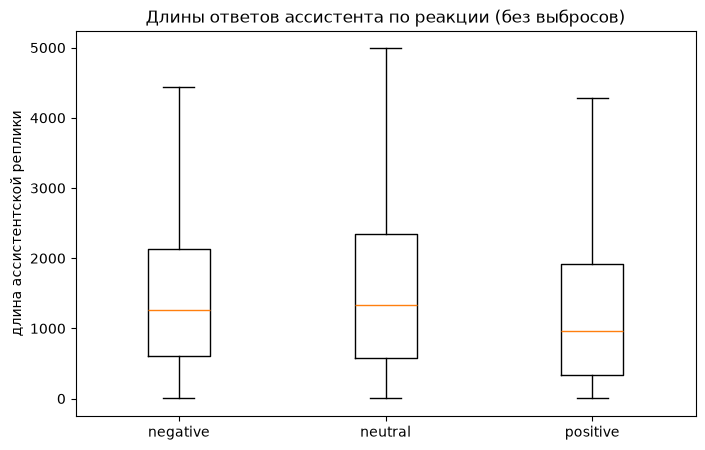

In [150]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(
    [lengths_by_label["negative"]["assistant"], lengths_by_label["neutral"]["assistant"], lengths_by_label["positive"]["assistant"]],
    tick_labels=["negative", "neutral", "positive"],
    showfliers=False,
)
ax.set_ylabel("длина ассистентской реплики")
ax.set_title("Длины ответов ассистента по реакции (без выбросов)")
plt.show()

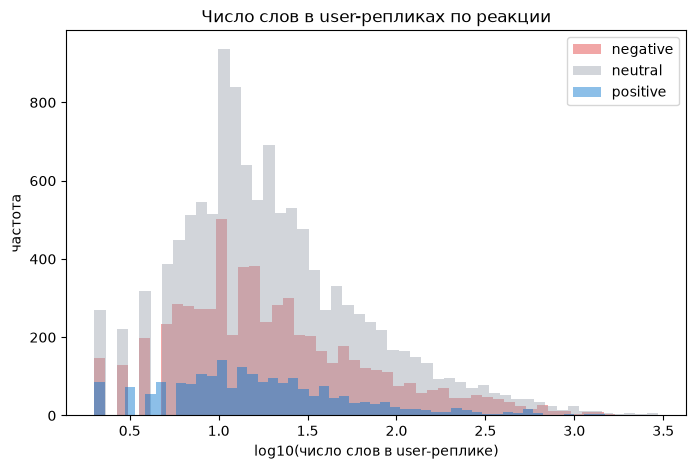

In [152]:
lengths_by_label = {}
for label in ['negative', 'neutral', 'positive']:
    mask = raw['reaction'] == label
    itog = raw[mask]

    len_wordsU = []
    len_wordsA = []
    quantity_wordsU = []
    quantity_wordsA = []

    for turns in itog['turns']:
        for turn in turns:
            if turn['role'] == 'user':
                len_wordsU.append(len(turn['text']))
                quantity_wordsU.append(len(turn['text'].split()))
            if turn['role'] == 'assistant':
                len_wordsA.append(len(turn['text']))
                quantity_wordsA.append(len(turn['text'].split()))

    lengths_by_label[label] = {"user": len_wordsU,"assistant": len_wordsA,"user_words": quantity_wordsU,"assistant_words": quantity_wordsA}

fig, ax = plt.subplots(figsize=(8, 5))
for label, color in [("negative", "#E03A3A"),("neutral", "#9CA3AF"),("positive", "#0072CE")]:
    words = np.array(lengths_by_label[label]["user_words"])
    ax.hist(
        np.log10(words + 1),
        bins=50,
        alpha=0.45,
        label=label,
        color=color,
    )

ax.set_xlabel("log10(число слов в user-реплике)")
ax.set_ylabel("частота")
ax.set_title("Число слов в user-репликах по реакции")
ax.legend()
plt.show()

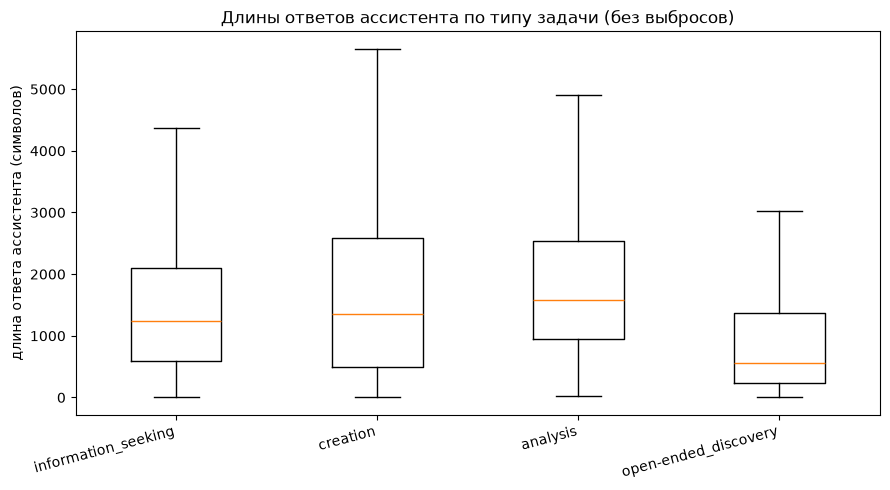

In [151]:
by_task_type = {}
for task in raw['task_type'].dropna().unique():
    mask = raw['task_type'] == task
    itog = raw[mask]
    assistant_lengths = []
    for turns in itog['turns']:
        for turn in turns:
            if turn['role'] == 'assistant':
                assistant_lengths.append(len(turn['text']))
    by_task_type[task] = assistant_lengths

fig, ax = plt.subplots(figsize=(9, 5))
order = ["information_seeking", "creation", "analysis", "open-ended_discovery"]
data = [by_task_type[task] for task in order]
ax.boxplot(
    data,
    tick_labels=order,
    showfliers=False,
)
ax.set_ylabel("длина ответа ассистента (символов)")
ax.set_title("Длины ответов ассистента по типу задачи (без выбросов)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

In [97]:
reaction_models = init_reaction_models(TRAIN_PATH)
reaction_labels = read_labels(LABELS_PATH, "reaction") if LABELS_PATH else {}

reaction_predictions, reaction_metrics = {}, {}
for name, model in reaction_models.items():
    reaction_predictions[name] = predict_reaction(model, dialogs)
    if reaction_labels:
        reaction_metrics[name] = compute_metrics(dialogs, reaction_predictions[name], reaction_labels)

pd.DataFrame(reaction_metrics).T.round(3)

,accuracy
dummy_most_frequent,0.591
dummy_stratified,0.455


In [98]:
topic_models = init_topic_models(TRAIN_PATH)
topic_labels = read_labels(LABELS_PATH, "topic") if LABELS_PATH else {}

topic_predictions, topic_metrics = {}, {}
for name, model in topic_models.items():
    topic_predictions[name] = predict_topic(model, dialogs)
    if topic_labels:
        topic_metrics[name] = compute_partition_metrics(dialogs, topic_predictions[name], topic_labels)

pd.DataFrame(topic_metrics).T.round(3)

""


In [99]:
save_predictions(PREDICTIONS_PATH, dialogs, {"reaction": reaction_predictions, "topic": topic_predictions})
print("строк в файле ответов:", len(dialogs) * (len(reaction_predictions) + len(topic_predictions)))

строк в файле ответов: 40000
